# EVM oppgave for IMAT3012 interaktiv økt

Vi skal bruke notatet for de interaktive deler av forelesningen. Her samler vi aktiviteter osv. for å bli bedre kjent med de numeriske metoder.

In [ ]:
#Kjør først: Vi trenger noen pakker
import numpy as np
import numpy.linalg as la
import matplotlib.pyplot as plt

%matplotlib inline 

## 1D Diffusjonsligning og EVM

Vi skal se på 1D diffusjonsligningsom fra forelesning som modellerer en kjølingsribbe i et teknisk system:

$$\frac{d^2}{dx^2}T + n^2(T-T_\infty) = 0, \qquad n=5m^{-1},\qquad T_V=100^\circ C,\qquad T_\infty = 20^\circ C$$

Lengden til ribben er $R=1m$, vi diskretiserer med 5 like store kontrollvolum av bredde $\delta x= 0.2m$.
Koeffisienter i diskretisert skjema er gitt som

| Node | $a_W$ | $a_E$ | $S^u$       | $S_P$ | $a_P=a_W+a_E-S_P$ |
|------|-------|-------|-------------|-------|-------------------|
| $1$  | $0$   | $5$   | $100+10T_V$ | $-15$ | $20$              |
| $2$  | $5$   | $5$   | $100$       | $-5$  | $15$              |
| $3$  | $5$   | $5$   | $100$       | $-5$  | $15$              |
| $4$  | $5$   | $5$   | $100$       | $-5$  | $15$              |
| $5$  | $5$   | $0$   | $100$       | $-5$  | $10$              |

Under ligger programkoden som er ikke ferdigstilt men inneholder de viktigste kommandoer for en Python implementering av problemet.

In [ ]:
#Rutenettgenerering
m=5
x = np.array([0.1,0.3,0.5,0.7,0.9]) # KV-inndeling
deltax = 0.2

#Diskretisering
koeff_diag  = np.array([????])
koeff_over  = np.array([????])
koeff_under = np.array([????])

L = np.diag( koeff_over  ,  1) + np.diag( koeff_under , -1) + np.diag(koeff_diag, 0)

F = np.zeros((m)) #Lagre en vektor av riktig lengde

#Løsning til lineært system
u = la.solve(L, F)

# Nå plotter vi løsning i koordinatsystem
plt.plot(???,???) 

## Oppgaver (på papir!)

a) Diskretisering er lagt ved bruk av ligningen $$a_PT_P = a_WT_W +a_ET_E+S^u.$$ Lag en matrise $L$ og en vektor $F$ slik at diskretisert system samsvarer med $$L \cdot \begin{bmatrix}T_1 \\ T_2 \\ T_3 \\ T_4 \\ T_5\end{bmatrix}= F$$

b) Matrisen $L$ fra del a) har en trebånd struktur. Forklar hvilket prinsipp fra EVM strukturen i matrisa uttrykker og hvordan strukturen lages ved hjelp av Python kode.

## Oppgaver (Python koding)

c) Ferdigstil kodeeksempel (neste cellen har en kopi av koden over): Legg inn matrisa $L$ og vektoren $F$ du har beregnet i a) slik at koden faktisk løser riktig lineær system og deretter plotter løsning.

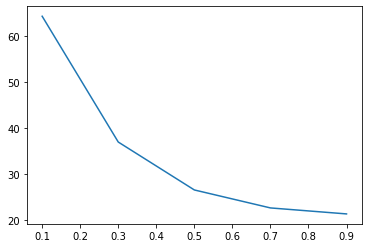

In [ ]:
#Rutenettgenerering
m=5
x = np.array([0.1,0.3,0.5,0.7,0.9]) # KV-inndeling/sentrale punkter i KV
deltax = 0.2

#Diskretisering
koeff_diag  = np.array([20,15,15,15,10])
koeff_over  = np.array([-5,-5,-5,-5])
koeff_under = np.array([-5,-5,-5,-5])

L = np.diag( koeff_over  ,  1) + np.diag( koeff_under , -1) + np.diag(koeff_diag, 0)

F = np.zeros((m)) #Lagre en vektor av riktig lengde
F[0]=100+10*100
F[1]=100
F[2]=100
F[3]=100
F[4]=100

#Løsning til lineært system
u = la.solve(L, F)

# Nå plotter vi løsning i koordinatsystem
plt.plot(x,u) 

d) Analytisk løsning til problemet er gitt ved funksjonen $$\frac{T(x) - T_\infty}{T_V - T_\infty} = \frac{\cosh\left(n(R - x)\right)}{\cosh(nR)} \qquad \text{hvor } \cosh(x)=\frac{e^x+e^{-x}}{2}.$$ Kompleter koden under slik at det sammenligner løsningen din fra c) med analytisk løsning til problemet.   

Maksimal feil i EVM approksimasjon er  4.29859555918955


<function matplotlib.pyplot.show(close=None, block=None)>

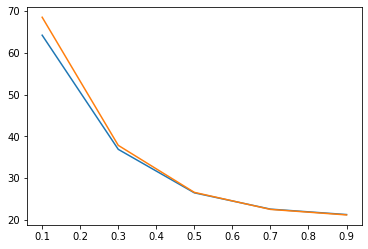

In [10]:
#Definer konstanter for problemet
R   = 1
n   = 5
TV  = 100
Tinf= 20

#Definer analytisk løsning
T =lambda x: (TV-Tinf)*np.cosh(n*(R-x))/(np.cosh(n*R))+Tinf

#Beregn feil for sentrale noder

absolut_feil = np.abs(u - T(x))

maks_feil = np.max(absolut_feil)

print("Maksimal feil i EVM approksimasjon er ", maks_feil)

plt.plot(x,u) 
plt.plot(x,T(x)) 
plt.show